<a href="https://colab.research.google.com/github/Janani-Hendeniya/EN3160-Assignment-02/blob/main/230238R_a02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3160 Assignment 02 — Fitting and Alignment

## Question 1: Blob Detection Using LoG

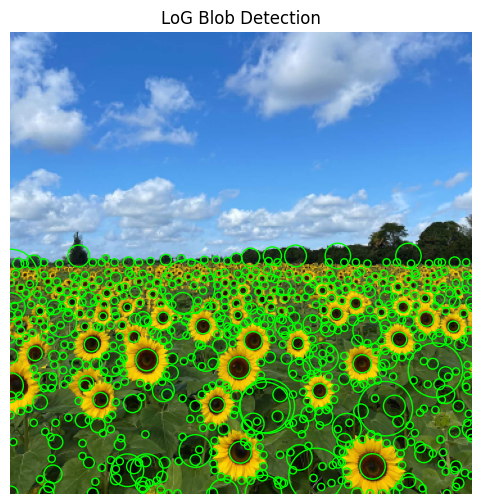

Detected circles: 657
Sigma range: 2 to 15


In [18]:

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter

# Load image and convert to grayscale
image = cv.imread("the_berry_farms_sunflower_field.jpeg",
                  cv.IMREAD_REDUCED_COLOR_4)

if image is None:
    raise FileNotFoundError("Sunflower image not found")

gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY).astype(float)
image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)

# Build scale-normalized LoG scale-space for dark blobs
sigmas = np.arange(2, 16)

scale_space = np.stack([
    np.maximum(s**2 * gaussian_laplace(gray, sigma=s), 0)
    for s in sigmas
])

# Detect 3D local maxima above threshold
maxima = maximum_filter(scale_space, size=(3, 3, 3))
mask = (scale_space == maxima) & (
    scale_space > 0.15 * scale_space.max()
)

# Extract circles below the horizon
horizon = int(gray.shape[0] * 0.48)
circles = []

for k, y, x in np.argwhere(mask):
    if y >= horizon:
        circles.append((x, y, np.sqrt(2) * sigmas[k]))

# Display detected circles
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(image_rgb)

for x, y, r in circles:
    ax.add_patch(plt.Circle((x, y), r,
                            fill=False, color="lime", lw=1))

ax.set_title("LoG Blob Detection")
ax.axis("off")
plt.show()

print("Detected circles:", len(circles))
print("Sigma range:", sigmas[0], "to", sigmas[-1])


Reporting largest circles

In [17]:

# Report 10 largest detected circles
largest = sorted(circles, key=lambda c: c[2], reverse=True)[:10]

print("Largest detected circles (pixels):")
print("No.    X     Y     Radius     Sigma")

for i, (x, y, r) in enumerate(largest, 1):
    print(f"{i:<6} {x:<5} {y:<5} {r:>7.2f} {r/np.sqrt(2):>9.2f}")


Largest detected circles (pixels):
No.    X     Y     Radius     Sigma
1      0     190     21.21     15.00
2      138   198     21.21     15.00
3      331   263     21.21     15.00
4      200   291     21.21     15.00
5      292   293     21.21     15.00
6      238   345     21.21     15.00
7      198   292     19.80     14.00
8      197   359     14.14     10.00
9      144   326     12.73      9.00
10     91    341     12.73      9.00


Methodology

The sunflower field image was converted to grayscale, and scale-normalized Laplacian of Gaussian (LoG) filtering was applied over a range of $\sigma = 2$ to $15$, with a step size of $1$. Positive LoG responses were retained to detect dark-centred blobs. Local maxima were identified in the three-dimensional scale-space using a $3 \times 3 \times 3$ neighbourhood, with a response threshold of 15% of the maximum response. A spatial mask was applied to exclude the sky region.

Results

Detected blob centres were represented by circles with radii calculated using:

$$r = \sqrt{2}\sigma$$

The resulting circles had radii ranging from approximately 2.83 to 21.21 pixels. The largest detected circles were identified based on their estimated radii.

Discussion

The detector identified many dark sunflower centres, although some false detections occurred around leaves, background vegetation, and other dark regions. Restricting detections to the lower portion of the image reduced unwanted sky detections. However, the method remains sensitive to the selected scale range and response threshold.